# GitHub Repository Popularity Analysis
**Statistical Inference Project

**Research question:** How are GitHub repository characteristics associated with popularity, and can we predict star counts or high/low popularity?

**How to run:** Google Colab → Runtime → Run all. Each small code cell performs one task. Every graph has its own cell. The GitHub API requires internet access. Run the Gradio cell last.

**Important:** The API returns a selected sample of recently updated repositories with at least 10 stars, **not** a random sample of all GitHub repositories. Statistical findings describe this collected dataset.

## Setup : Libraries

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [3]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay

In [5]:
SEED = 42
LANGUAGES = ["Python", "JavaScript", "Java", "C++", "Go", "Rust"]
sns.set_theme(style="whitegrid")


## Practical 1 : Web Scraping and Data Collection
**Aim:** Demonstrate HTML scraping using BeautifulSoup and collect repository records using the GitHub REST API.

**Why two approaches?** BeautifulSoup reads HTML; the GitHub API supplies reliable structured JSON for our actual analysis.

### 1A. Small HTML web-scraping demonstration

In [6]:
from bs4 import BeautifulSoup
html = requests.get("https://github.com/pallets/flask", timeout=20, headers={"User-Agent": "SI-Education-Project"})
html.raise_for_status()

In [7]:
soup = BeautifulSoup(html.text, "html.parser")
print("Scraped page title:", soup.title.get_text(" ", strip=True) if soup.title else "No title found")

Scraped page title: GitHub - pallets/flask: The Python micro framework for building web applications. · GitHub


### 1B. GitHub API collection (100 repositories per language)

In [8]:
API_URL = "https://api.github.com/search/repositories"
RAW_CSV = "github_raw_data.csv"

In [9]:
def fetch_repos(language):
    params = {"q": f'language:"{language}" stars:>=10',
              "sort": "updated", "order": "desc", "per_page": 100}
    response = requests.get(API_URL, params=params, timeout=30,
                            headers={"Accept": "application/vnd.github+json", "User-Agent": "SI-Education-Project"})
    response.raise_for_status()
    return response.json()["items"]

The next cell uses a previously saved CSV if available. Otherwise, it requests fresh API data. GitHub unauthenticated search has rate limits; wait and retry if you received HTTP 403/429.

In [10]:
import os
if os.path.exists(RAW_CSV):
    df_raw = pd.read_csv(RAW_CSV)
    print("Loaded existing CSV")
else:
    records = []
    for lang in LANGUAGES:
        print("Fetching:", lang)
        items = fetch_repos(lang)
        for repo in items:
            records.append({"name": repo["full_name"], "language": lang,
                            "stars": repo["stargazers_count"], "forks": repo["forks_count"],
                            "open_issues": repo["open_issues_count"], "size": repo["size"],
                            "created_at": repo["created_at"], "updated_at": repo["updated_at"],
                            "license": repo["license"]["name"] if repo.get("license") else None})
    df_raw = pd.DataFrame(records)
    df_raw.to_csv(RAW_CSV, index=False)
    print("Saved:", RAW_CSV)

Fetching: Python
Fetching: JavaScript
Fetching: Java
Fetching: C++
Fetching: Go
Fetching: Rust
Saved: github_raw_data.csv


In [11]:
print("Rows and columns:", df_raw.shape)

Rows and columns: (600, 9)


In [12]:
display(df_raw.head())

,name,language,stars,forks,open_issues,size,created_at,updated_at,license
0,ipitio/backage,Python,61,18,0,14066009,2024-06-08T09:11:40Z,2026-10-27T01:06:23Z,MIT License
1,simonw/simonwillisonblog-backup,Python,50,2,1,163462,2020-08-17T20:21:17Z,2026-10-27T01:06:22Z,None
2,amazeyourself/tamil-local-iptv,Python,27,3,2,21002,2025-09-05T05:05:15Z,2026-10-27T01:06:21Z,None
3,kirodotdev/KiroCrew,Python,4585,881,3106,3230117,2026-07-16T21:21:54Z,2026-10-27T01:06:08Z,Apache License 2.0
4,Brajesh31/fastapi-py,Python,10,0,0,51,2025-07-23T21:25:25Z,2026-10-27T01:06:10Z,None


In [13]:
display(df_raw["language"].value_counts())

,count
language,
Python,100
JavaScript,100
Java,100
C++,100
Go,100
Rust,100


**Interpretation:** Each row is a repository. Stars are our popularity indicator. The CSV allows later runs without repeating the API requests.


## Practical 2 : Data Cleaning, EDA and Visualization

In [14]:
df = df_raw.copy()

### Check missing values

In [15]:
print(df.isnull().sum())

name            0
language        0
stars           0
forks           0
open_issues     0
size            0
created_at      0
updated_at      0
license        88
dtype: int64


### Check duplicate repositories

In [16]:
print("Duplicate repository names:", df["name"].duplicated().sum())

Duplicate repository names: 0


### Remove duplicate repositories

In [17]:
df = df.drop_duplicates(subset="name").copy()
print("Rows remaining:", len(df))

Rows remaining: 600


### Handle missing license values

In [18]:
df["license"] = df["license"].fillna("Unknown")

### Convert numeric columns

In [19]:
numeric_cols = ["stars", "forks", "open_issues", "size"]
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")

### Convert date columns

In [20]:
df["created_at"] = pd.to_datetime(df["created_at"], utc=True, errors="coerce")
df["updated_at"] = pd.to_datetime(df["updated_at"], utc=True, errors="coerce")

### Remove rows missing essential fields

In [21]:
df = df.dropna(subset=numeric_cols + ["language", "created_at"]).copy()
print("Cleaned rows:", len(df))

Cleaned rows: 600


### Calculate repository age

In [22]:
today = pd.Timestamp.now(tz="UTC")
df["age_years"] = ((today - df["created_at"]).dt.days / 365.25).clip(lower=0)

### Verify missing values

In [23]:
print(df.isnull().sum())

name           0
language       0
stars          0
forks          0
open_issues    0
size           0
created_at     0
updated_at     0
license        0
age_years      0
dtype: int64


### Descriptive statistics

In [24]:
display(df[["stars", "forks", "open_issues", "size", "age_years"]].describe().round(2))

,stars,forks,open_issues,size,age_years
count,600.00,600.00,600.00,600.00,600.00
mean,3413.60,623.33,212.63,628794.36,3.32
std,14794.35,3861.91,846.78,2942581.62,4.13
min,10.00,0.00,0.00,46.00,0.00
25%,22.00,3.00,1.00,10063.50,0.38
50%,71.50,15.00,8.00,49106.00,1.23
75%,508.75,109.25,63.25,236736.50,5.56
max,201284.00,78704.00,10491.00,36876240.00,16.71


### Save cleaned data

In [25]:
df.to_csv("github_cleaned_data.csv", index=False)
print("Saved github_cleaned_data.csv")

Saved github_cleaned_data.csv


### Stars histogram

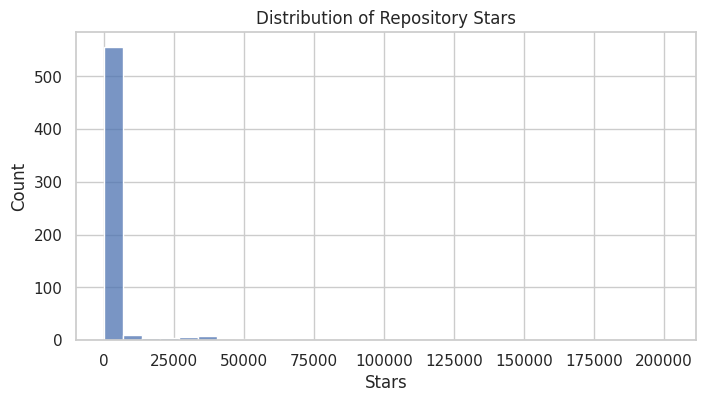

In [26]:
plt.figure(figsize=(8, 4))
sns.histplot(df["stars"], bins=30)
plt.title("Distribution of Repository Stars")
plt.xlabel("Stars")
plt.show()

###  Log-stars histogram (makes skew easier to see)

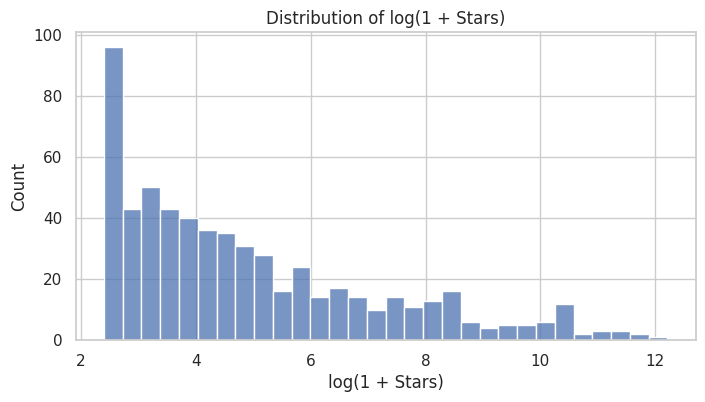

In [27]:
plt.figure(figsize=(8, 4))
sns.histplot(np.log1p(df["stars"]), bins=30)
plt.title("Distribution of log(1 + Stars)")
plt.xlabel("log(1 + Stars)")
plt.show()

###  Number of repositories by language

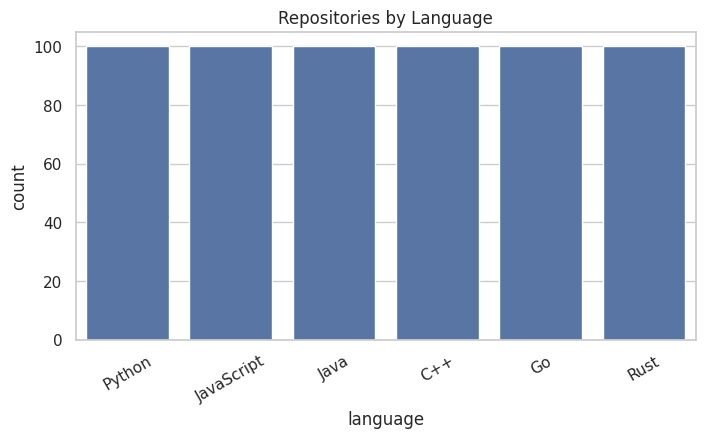

In [28]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="language", order=LANGUAGES)
plt.title("Repositories by Language")
plt.xticks(rotation=30)
plt.show()

### Stars by language (log scale)

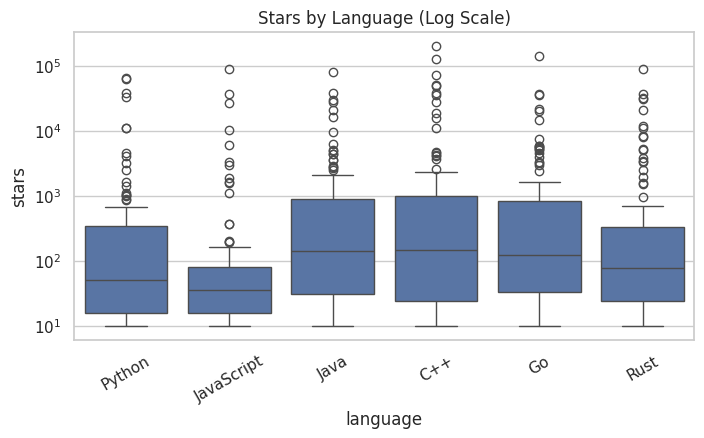

In [29]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="language", y="stars", order=LANGUAGES)
plt.yscale("log")
plt.title("Stars by Language (Log Scale)")
plt.xticks(rotation=30)
plt.show()



### Stars versus forks

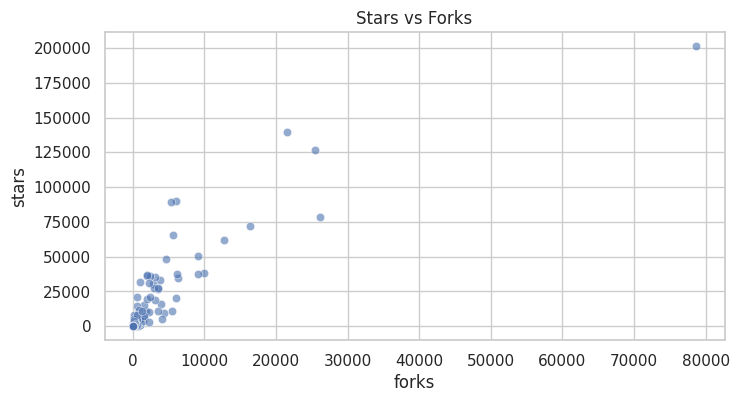

In [30]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x="forks", y="stars", alpha=0.6)
plt.title("Stars vs Forks")
plt.show()

### Stars versus age


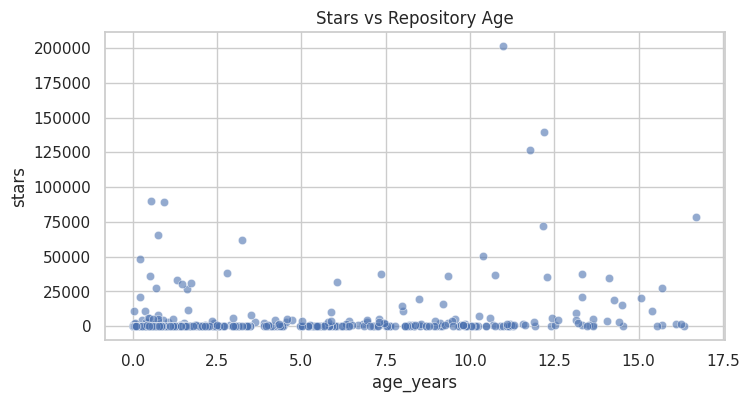

In [31]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x="age_years", y="stars", alpha=0.6)
plt.title("Stars vs Repository Age")
plt.show()

**Interpretation:** Describe what your graphs actually show after running them. Star counts are commonly skewed, so log-scale plots help display low and high values together.

## Practical 3 : Distributions and Sampling

### Mean, median and standard deviation

In [32]:
print("Mean:", round(df["stars"].mean(), 2))
print("Median:", round(df["stars"].median(), 2))
print("Standard deviation:", round(df["stars"].std(), 2))

Mean: 3413.6
Median: 71.5
Standard deviation: 14794.35


### Skewness

In [33]:
print("Skewness:", round(df["stars"].skew(), 2))

Skewness: 7.89


### Empirical probability

In [34]:
threshold = df["stars"].median()
print("P(Stars > median):", round((df["stars"] > threshold).mean(), 3))

P(Stars > median): 0.5


### Simple random sampling

In [35]:
sample_n = min(30, len(df))
simple_sample = df.sample(n=sample_n, random_state=SEED)
display(simple_sample.head())

,name,language,stars,forks,open_issues,size,created_at,updated_at,license,age_years
110,nextcloud/files_mindmap,JavaScript,197,52,35,8542,2018-09-29 02:46:51+00:00,2026-10-27 01:05:11+00:00,GNU Affero General Public License v3.0,8.073922
419,vynulldev/vynull,Go,32,1,8,3186,2026-07-01 22:28:55+00:00,2026-10-27 01:04:51+00:00,GNU General Public License v3.0,0.320329
565,Dicklesworthstone/remote_compilation_helper,Rust,68,4,30,139457,2026-01-16 07:42:34+00:00,2026-10-27 01:02:35+00:00,Other,0.774812
77,c-wilkinson/StravaDataAnalysis,Python,21,2,3,36876240,2021-03-11 13:07:38+00:00,2026-10-27 01:03:53+00:00,The Unlicense,5.626283
181,nextcloud/files_antivirus,JavaScript,114,44,108,5877,2016-09-02 08:09:36+00:00,2026-10-27 00:57:24+00:00,GNU Affero General Public License v3.0,10.146475


### Systematic sampling (after shuffling)

In [36]:
shuffled = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
systematic_sample = shuffled.iloc[np.linspace(0, len(df)-1, sample_n, dtype=int)]
print("Systematic sample size:", len(systematic_sample))

Systematic sample size: 30


### Stratified sampling (proportional to language counts)

In [37]:
counts = df["language"].value_counts().sort_index()
quotas = counts / len(df) * sample_n
allocation = np.floor(quotas).astype(int)
remainder = sample_n - allocation.sum()
for lang in (quotas - allocation).sort_values(ascending=False).index[:remainder]:
    allocation[lang] += 1

In [38]:
stratified_sample = pd.concat([
    df[df["language"] == lang].sample(n=int(count), random_state=SEED)
    for lang, count in allocation.items() if count > 0
])
print("Stratified sample size:", len(stratified_sample))

Stratified sample size: 30


### Cluster sampling (select two entire language groups)

In [39]:
chosen = np.random.default_rng(SEED).choice(df["language"].unique(), 2, replace=False)
cluster_sample = df[df["language"].isin(chosen)]
print("Languages:", chosen, "Rows:", len(cluster_sample))

Languages: ['Python' 'Go'] Rows: 200


### Compare sample means

In [40]:
sample_means_table = pd.DataFrame({
    "Group": ["Full dataset", "Simple", "Systematic", "Stratified", "Cluster"],
    "Mean stars": [df.stars.mean(), simple_sample.stars.mean(), systematic_sample.stars.mean(),
                   stratified_sample.stars.mean(), cluster_sample.stars.mean()]
})
display(sample_means_table.round(2))

,Group,Mean stars
0,Full dataset,3413.60
1,Simple,120.40
2,Systematic,3956.73
3,Stratified,4713.33
4,Cluster,2990.82


### Compare sample mean stars

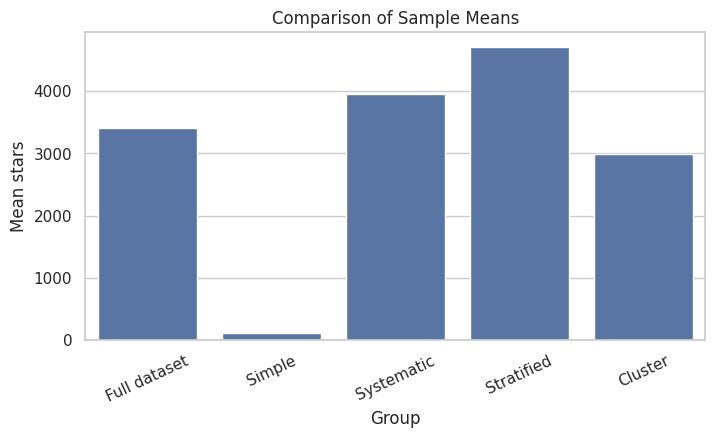

In [41]:
plt.figure(figsize=(8, 4))
sns.barplot(data=sample_means_table, x="Group", y="Mean stars")
plt.xticks(rotation=25)
plt.title("Comparison of Sample Means")
plt.show()

**Interpretation:** Sampling methods select different subsets, so sample means can differ from the collected dataset mean. Cluster sampling may contain more than 30 repositories.

## Practical 4 : Central Limit Theorem (CLT)

### Sampling function (repeated sampling with replacement)

In [42]:
def sample_means(n, repetitions=1000):
    rng = np.random.default_rng(SEED)
    samples = rng.choice(df["stars"].to_numpy(), size=(repetitions, n), replace=True)
    return samples.mean(axis=1)

### CLT sample size 5

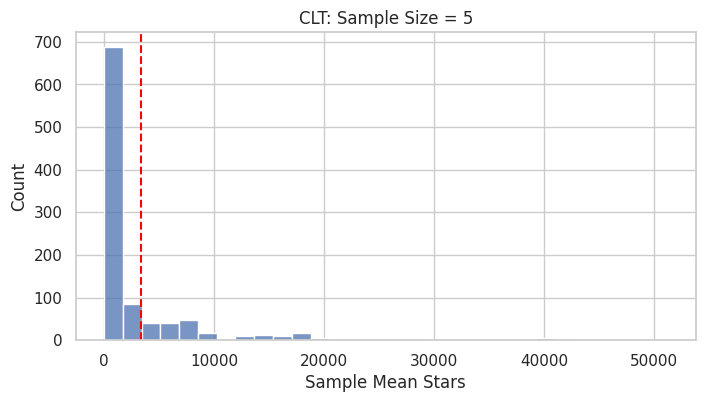

In [43]:
plt.figure(figsize=(8, 4))
means_5 = sample_means(5)
sns.histplot(means_5, bins=30)
plt.axvline(df["stars"].mean(), color="red", linestyle="--")
plt.title("CLT: Sample Size = 5")
plt.xlabel("Sample Mean Stars")
plt.show()

### CLT sample size 10

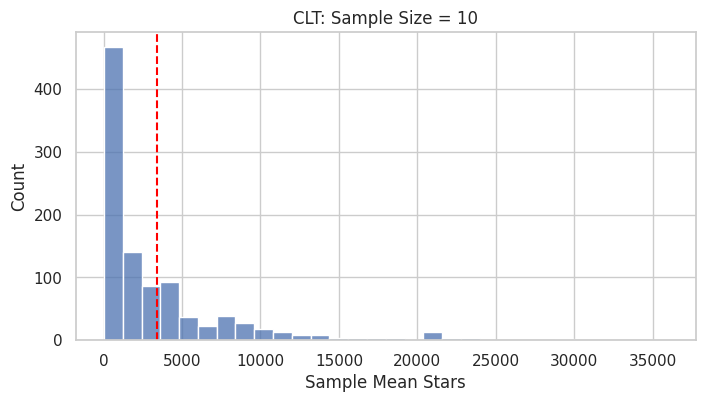

In [44]:
plt.figure(figsize=(8, 4))
means_10 = sample_means(10)
sns.histplot(means_10, bins=30)
plt.axvline(df["stars"].mean(), color="red", linestyle="--")
plt.title("CLT: Sample Size = 10")
plt.xlabel("Sample Mean Stars")
plt.show()

###CLT sample size 30

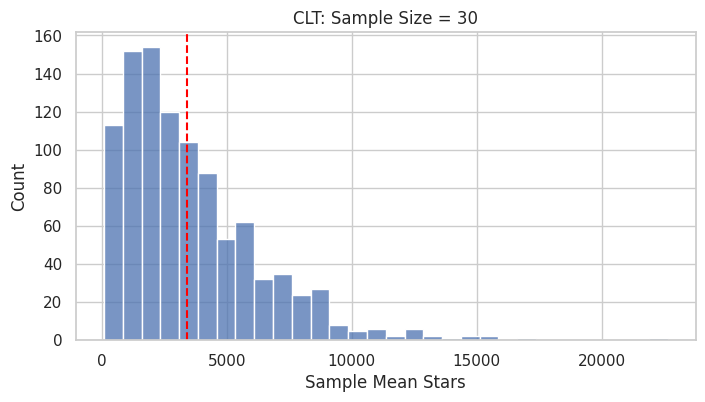

In [45]:
plt.figure(figsize=(8, 4))
means_30 = sample_means(30)
sns.histplot(means_30, bins=30)
plt.axvline(df["stars"].mean(), color="red", linestyle="--")
plt.title("CLT: Sample Size = 30")
plt.xlabel("Sample Mean Stars")
plt.show()

###CLT sample size 50

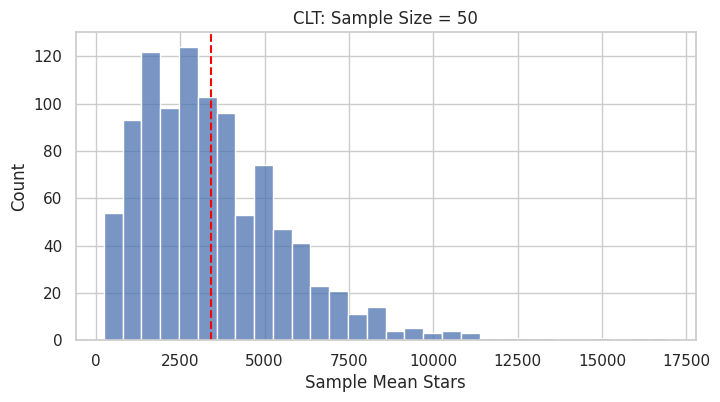

In [46]:
plt.figure(figsize=(8, 4))
means_50 = sample_means(50)
sns.histplot(means_50, bins=30)
plt.axvline(df["stars"].mean(), color="red", linestyle="--")
plt.title("CLT: Sample Size = 50")
plt.xlabel("Sample Mean Stars")
plt.show()

### Compare standard errors

In [47]:
clt_table = pd.DataFrame({
    "Sample size": [5, 10, 30, 50],
    "SD of sample means": [means_5.std(), means_10.std(), means_30.std(), means_50.std()]
})
display(clt_table.round(2))

,Sample size,SD of sample means
0,5,6337.13
1,10,4859.30
2,30,2757.47
3,50,2225.53


**Interpretation:** As sample size increases, the distribution of sample means generally becomes more concentrated around the dataset mean. With very skewed data, normality may require larger samples.

## Practical 5 : Hypothesis Testing

In [48]:
alpha = 0.05
python_stars = df.loc[df["language"] == "Python", "stars"]
java_stars = df.loc[df["language"] == "Java", "stars"]


### Independent two-sample T-test (Python vs Java)

In [49]:
t_stat, t_p = stats.ttest_ind(python_stars, java_stars)
print("T-statistic:", round(t_stat, 3))
print("P-value:", round(t_p, 5))


T-statistic: -0.231
P-value: 0.8173


In [50]:
print("Reject H0" if t_p < alpha else "Do not reject H0")
print("H0: Mean stars are equal for Python and Java")


Do not reject H0
H0: Mean stars are equal for Python and Java


### One-way ANOVA on all six languages

In [51]:
groups = [df.loc[df["language"] == lang, "stars"] for lang in LANGUAGES]
f_stat, anova_p = stats.f_oneway(*groups)
print("F-statistic:", round(f_stat, 3))
print("P-value:", round(anova_p, 5))


F-statistic: 1.492
P-value: 0.19048


In [52]:
print("Reject H0" if anova_p < alpha else "Do not reject H0")
print("H0: All languages have the same mean stars")


Do not reject H0
H0: All languages have the same mean stars


### Create popularity category for Chi-Square

In [53]:
median_stars = df["stars"].median()
df["popularity"] = np.where(df["stars"] > median_stars, "High", "Low")

### Contingency table

In [54]:
contingency = pd.crosstab(df["language"], df["popularity"])
display(contingency)

popularity,High,Low
language,,
C++,60,40
Go,59,41
Java,58,42
JavaScript,28,72
Python,43,57
Rust,52,48


### Chi-Square independence test

In [55]:
chi2, chi_p, dof, expected = stats.chi2_contingency(contingency)
print("Chi-Square:", round(chi2, 3))
print("P-value:", round(chi_p, 5))
print("Smallest expected frequency:", round(expected.min(), 2))

Chi-Square: 31.28
P-value: 1e-05
Smallest expected frequency: 50.0


In [56]:
print("Reject H0" if chi_p < alpha else "Do not reject H0")
print("H0: Language and popularity category are independent")

Reject H0
H0: Language and popularity category are independent


## Practical 6 : Covariance and Correlation

In [57]:
analysis_cols = ["stars", "forks", "open_issues", "size", "age_years"]

### Covariance matrix

In [58]:
display(df[analysis_cols].cov().round(2))

,stars,forks,open_issues,size,age_years
stars,2.188728e+08,4.968489e+07,7.251339e+06,3.695536e+09,14677.72
forks,4.968489e+07,1.491437e+07,1.652034e+06,7.392782e+08,3812.76
open_issues,7.251339e+06,1.652034e+06,7.170444e+05,3.344168e+08,787.47
size,3.695536e+09,7.392782e+08,3.344168e+08,8.658787e+12,946548.20
age_years,1.467772e+04,3.812760e+03,7.874700e+02,9.465482e+05,17.06


### Pearson correlation matrix

In [59]:
pearson = df[analysis_cols].corr(method="pearson")
display(pearson.round(2))

,stars,forks,open_issues,size,age_years
stars,1.00,0.87,0.58,0.08,0.24
forks,0.87,1.00,0.51,0.07,0.24
open_issues,0.58,0.51,1.00,0.13,0.23
size,0.08,0.07,0.13,1.00,0.08
age_years,0.24,0.24,0.23,0.08,1.00


### Spearman correlation matrix

In [60]:
spearman = df[analysis_cols].corr(method="spearman")
display(spearman.round(2))

,stars,forks,open_issues,size,age_years
stars,1.00,0.87,0.55,0.38,0.35
forks,0.87,1.00,0.61,0.43,0.47
open_issues,0.55,0.61,1.00,0.40,0.28
size,0.38,0.43,0.40,1.00,0.23
age_years,0.35,0.47,0.28,0.23,1.00


###  Pearson heatmap

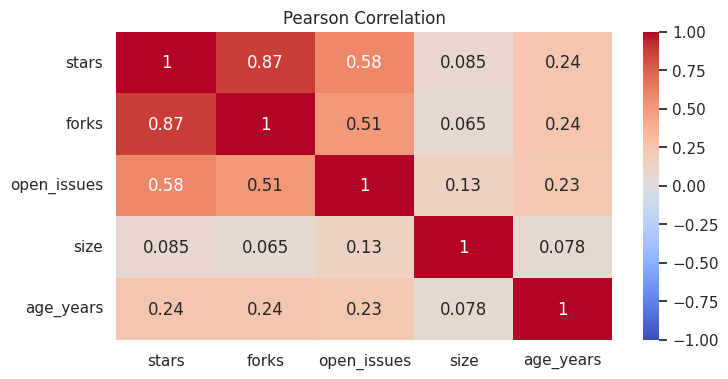

In [61]:
plt.figure(figsize=(8, 4))
sns.heatmap(pearson, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson Correlation")
plt.show()

###  Spearman heatmap

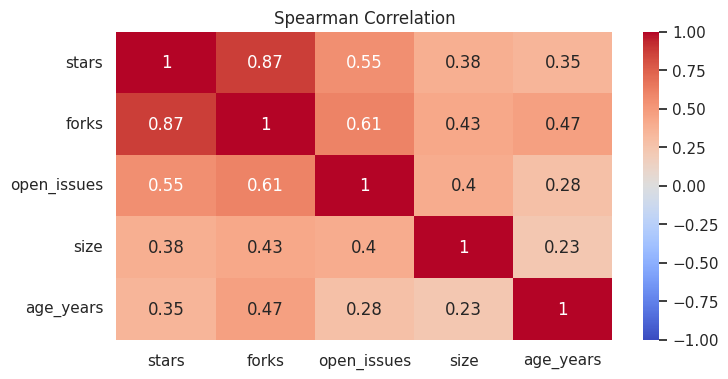

In [62]:
plt.figure(figsize=(8, 4))
sns.heatmap(spearman, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman Correlation")
plt.show()

**Interpretation:** Pearson measures linear relationships; Spearman measures rank-based monotonic relationships. Neither establishes causation.

**Features:** forks, open issues, size, age, and language. **Regression target:** stars. We do not use stars as a feature. Models describe associations using contemporaneous repository statistics, not future popularity.

In [63]:
features = ["forks", "open_issues", "size", "age_years", "language"]
X = pd.get_dummies(df[features], columns=["language"], dtype=int)
y = df["stars"].astype(float)

### Train-test split

In [64]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print("Training:", len(X_train_reg), "Testing:", len(X_test_reg))

Training: 480 Testing: 120


## Practical 7 : Regression (Predict Number of Stars)

**Target:** Number of stars. **Metrics:** MAE, RMSE and R². Five regression models from Practical 7 are compared. No extra target transformation is used.


In [65]:
# Regression target is already stored in y_train_reg
print("Training rows:", len(y_train_reg))


Training rows: 480


### Create regression models

In [66]:
regression_models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=10000)),
    "Decision Tree": DecisionTreeRegressor(max_depth=4, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=6, random_state=SEED)
}

### Train models (one simple loop)

In [67]:
for name, model in regression_models.items():
    model.fit(X_train_reg, y_train_reg)
    print("Trained:", name)


Trained: Linear Regression
Trained: Ridge
Trained: Lasso
Trained: Decision Tree
Trained: Random Forest


### Calculate regression metrics

In [68]:
regression_scores = []
for name, model in regression_models.items():
    predicted = model.predict(X_test_reg)
    mae = mean_absolute_error(y_test_reg, predicted)
    rmse = np.sqrt(mean_squared_error(y_test_reg, predicted))
    r2 = r2_score(y_test_reg, predicted)
    regression_scores.append([name, mae, rmse, r2])


### Display model comparison

In [69]:
regression_table = pd.DataFrame(regression_scores, columns=["Model", "MAE", "RMSE", "R2"])
regression_table = regression_table.sort_values("MAE")
display(regression_table.round(3))

,Model,MAE,RMSE,R2
4,Random Forest,1265.450,4378.277,0.904
2,Lasso,2330.372,6123.676,0.811
0,Linear Regression,2330.471,6123.713,0.811
1,Ridge,2331.616,6131.482,0.811
3,Decision Tree,2489.363,13548.529,0.077


###  Regression MAE comparison

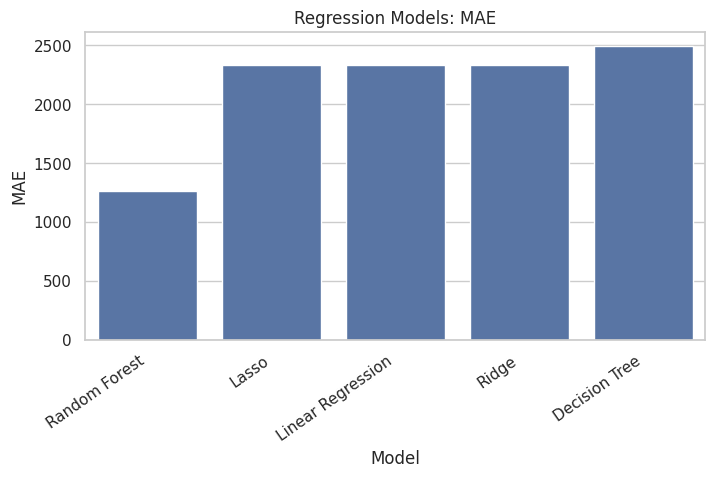

In [70]:
plt.figure(figsize=(8, 4))
sns.barplot(data=regression_table, x="Model", y="MAE")
plt.xticks(rotation=35, ha="right")
plt.title("Regression Models: MAE")
plt.show()

### Actual vs predicted stars (best regression model)

In [71]:
best_reg_name = regression_table.iloc[0]["Model"]
best_reg = regression_models[best_reg_name]
best_reg_predictions = best_reg.predict(X_test_reg)
print("Best regression model:", best_reg_name)


Best regression model: Random Forest


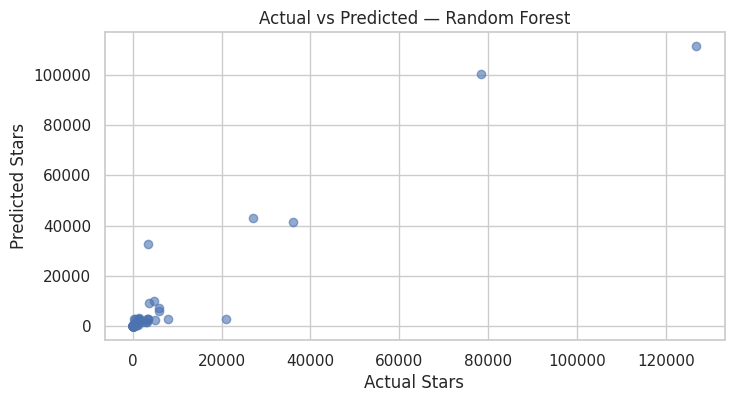

In [72]:
plt.figure(figsize=(8, 4))
plt.scatter(y_test_reg, best_reg_predictions, alpha=0.6)
plt.xlabel("Actual Stars")
plt.ylabel("Predicted Stars")
plt.title("Actual vs Predicted — " + best_reg_name)
plt.show()

## Practical 8 : Classification (High vs Low Popularity)

We calculate the popularity cutoff **only from training stars** to avoid test-data leakage. High popularity = stars above training median. Models use the same features as regression.

In [73]:
cutoff = y_train_reg.median()
y_train_cls = (y_train_reg > cutoff).astype(int)
y_test_cls = (y_test_reg > cutoff).astype(int)
X_train_cls = X_train_reg.copy()
X_test_cls = X_test_reg.copy()
print("Popularity cutoff:", cutoff, "stars")
print("Training classes:")
print(y_train_cls.value_counts())

Popularity cutoff: 71.5 stars
Training classes:
stars
0    240
1    240
Name: count, dtype: int64


### Create classification models

In [74]:
classification_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "SVM": make_pipeline(StandardScaler(), SVC()),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=6, random_state=SEED),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
}

### Train classifiers

In [75]:
for name, model in classification_models.items():
    model.fit(X_train_cls, y_train_cls)
    print("Trained:", name)

Trained: Logistic Regression
Trained: SVM
Trained: Decision Tree
Trained: Random Forest
Trained: KNN


### Calculate classification metrics

In [76]:
classification_scores = []
for name, model in classification_models.items():
    predicted = model.predict(X_test_cls)
    classification_scores.append([name, accuracy_score(y_test_cls, predicted),
                                  precision_score(y_test_cls, predicted, zero_division=0),
                                  recall_score(y_test_cls, predicted, zero_division=0),
                                  f1_score(y_test_cls, predicted, zero_division=0)])

### Display classifier comparison

In [77]:
classification_table = pd.DataFrame(classification_scores, columns=["Model", "Accuracy", "Precision", "Recall", "F1"])
classification_table = classification_table.sort_values("F1", ascending=False)
display(classification_table.round(3))

,Model,Accuracy,Precision,Recall,F1
3,Random Forest,0.900,0.929,0.867,0.897
2,Decision Tree,0.867,0.879,0.850,0.864
0,Logistic Regression,0.725,0.800,0.600,0.686
4,KNN,0.683,0.704,0.633,0.667
1,SVM,0.692,0.795,0.517,0.626


### Classifier accuracy comparison

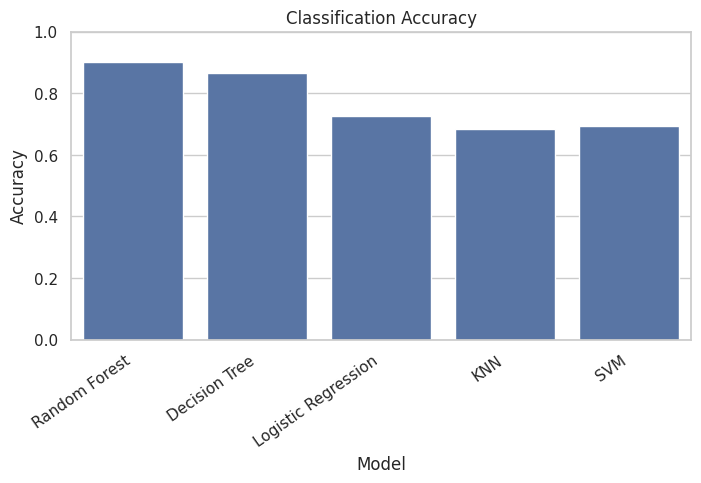

In [78]:
plt.figure(figsize=(8, 4))
sns.barplot(data=classification_table, x="Model", y="Accuracy")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.title("Classification Accuracy")
plt.show()

### Choose best classifier

In [79]:
best_name = classification_table.iloc[0]["Model"]
best_classifier = classification_models[best_name]
print("Best classifier by test F1:", best_name)

Best classifier by test F1: Random Forest


###  Confusion matrix

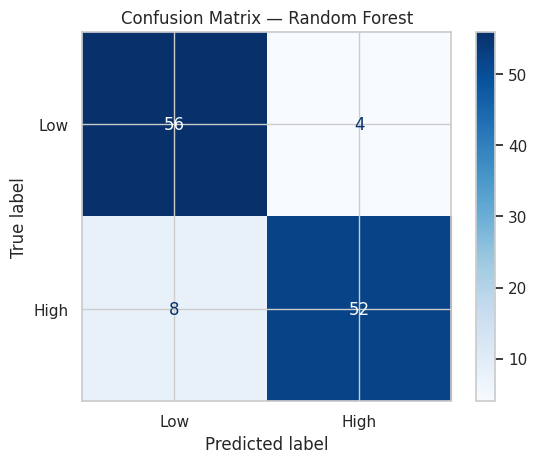

In [80]:
ConfusionMatrixDisplay.from_predictions(
    y_test_cls, best_classifier.predict(X_test_cls),
    labels=[0, 1], display_labels=["Low", "High"], cmap="Blues"
)
plt.title("Confusion Matrix — " + best_name)
plt.show()

**Interpretation:** A confusion matrix shows correct and incorrect predictions for both classes. Selecting the highest test F1 is a classroom demonstration; a separate validation set would be preferable for rigorous model selection.

## Gradio Interface

In [81]:
import gradio as gr
print("Gradio version:", gr.__version__)

Gradio version: 6.30.0


### Prediction function

In [82]:
def predict_popularity(language, forks, open_issues, size, age_years):
    row = pd.DataFrame(0.0, index=[0], columns=X_train_cls.columns)
    row["forks"] = float(forks)
    row["open_issues"] = float(open_issues)
    row["size"] = float(size)
    row["age_years"] = float(age_years)
    row["language_" + language] = 1.0
    row = row[X_train_cls.columns]
    prediction = best_classifier.predict(row)[0]
    return "High Popularity" if prediction == 1 else "Low Popularity"


### Test prediction without Gradio

In [83]:
print(predict_popularity("Python", 50, 10, 1000, 3))

High Popularity


### Check class predictions (correct classification labels)
These cells use `y_test_cls`, not regression star counts.

In [84]:
test_predictions = best_classifier.predict(X_test_cls)
print("Actual popularity categories:")
print(y_test_cls.value_counts().sort_index())
print("Predicted popularity categories:")
print(pd.Series(test_predictions).value_counts().sort_index())

Actual popularity categories:
stars
0    60
1    60
Name: count, dtype: int64
Predicted popularity categories:
0    64
1    56
Name: count, dtype: int64


In [85]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test_cls, test_predictions, labels=[0, 1]))

[[56  4]
 [ 8 52]]


### Real Low and High examples for Gradio
These examples come from actual test-set feature rows. Click them in the Gradio app to verify both prediction categories.


### Gradio app

In [89]:
app = gr.Interface(
    fn=predict_popularity,
    inputs=[
        gr.Dropdown(choices=LANGUAGES, value="Python", label="Language"),
        gr.Number(value=50, label="Forks"),
        gr.Number(value=10, label="Open issues"),
        gr.Number(value=1000, label="Repository size (KB)"),
        gr.Number(value=3, label="Repository age (years)")
    ],
    outputs=gr.Textbox(label="Predicted popularity"),
    examples=example_inputs,
    title="GitHub Repository Popularity Predictor",
    description="Try the example rows below for real Low and High predictions from the test dataset."
)


### Launching Gradio (Colab)

In [90]:
app.launch(share=True, inline=False, prevent_thread_lock=True, show_error=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://105e498b26e18176ca.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
